# 03 · Efficient attention for long contexts

Dense attention costs O(T²). This notebook implements and compares the main alternatives, all with the
same interface `forward(x, freqs_cis) -> (B, T, C)` so they drop into the same model:

| variant | pattern | cost | used by |
|---|---|---|---|
| dense causal | everything in the past | O(T²) | default; FlashAttention makes it memory-efficient |
| sliding window (SWA) | last `w` tokens | O(T·w) | Mistral, Gemma local layers, gpt-oss |
| Longformer | window + global tokens | O(T·(w+g)) | 2020 encoders; ancestor of hybrids |
| block-sparse (NSA/DSA) | top-k blocks chosen *by content* + local | O(T·k·b) | DeepSeek-V3.2, Kimi |
| linear | recurrent state, no softmax | O(T) | hybrids: Qwen3-Next, Kimi Linear, MiniMax |
| hybrid | mostly cheap layers + few dense | ~O(T) | Gemma 3 (5:1), Qwen3-Next (3:1) |

**Source:** `llmsuite/layers.py`.

In [1]:
import os, sys, math, time, tempfile
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llmsuite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # notebooks live in notebooks/<topic>/, so climb up to the repo root
sys.path.insert(0, ROOT)                            # so that `import llmsuite` works from the notebook
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from llmsuite.utils import seed_everything, get_device, count_params, human, show_mask
seed_everything(0)
device = get_device()
print("torch", torch.__version__, "| device", device)

torch 2.14.1+cu130 | device cuda


In [2]:
from llmsuite.layers import (causal_mask, sliding_window_mask, longformer_mask, precompute_freqs_cis,
                             SlidingWindowAttention, LongformerAttention, BlockSparseAttention, LinearAttention, GroupedQueryAttention)
T = 20
show_mask(causal_mask(T), "dense causal")
show_mask(sliding_window_mask(T, 5), "sliding window, w=5")
show_mask(longformer_mask(T, 5, [0, 10]), "Longformer, w=5, global={0,10}")


dense causal  — rows = query i, columns = key j
 0 █···················
 1 ██··················
 2 ███·················
 3 ████················
 4 █████···············
 5 ██████··············
 6 ███████·············
 7 ████████············
 8 █████████···········
 9 ██████████··········
10 ███████████·········
11 ████████████········
12 █████████████·······
13 ██████████████······
14 ███████████████·····
15 ████████████████····
16 █████████████████···
17 ██████████████████··
18 ███████████████████·
19 ████████████████████

sliding window, w=5  — rows = query i, columns = key j
 0 █···················
 1 ██··················
 2 ███·················
 3 ████················
 4 █████···············
 5 ·█████··············
 6 ··█████·············
 7 ···█████············
 8 ····█████···········
 9 ·····█████··········
10 ······█████·········
11 ·······█████········
12 ········█████·······
13 ·········█████······
14 ··········█████·····
15 ···········█████····
16 ············█████···
17 ····

## Sliding window: receptive field grows with depth

With `L` layers, information can travel `L·w` tokens (token *i* in layer 2 sees *i−w*, which in layer 1 saw *i−2w*…), like a CNN's receptive field. Exact retrieval of a far token degrades, which is why global layers are interleaved. Two bonus properties: the KV-cache can be a ring buffer of size `w`, and the model generalizes to lengths never seen in training (no token ever sees more than `w` positions).

A boolean mask in SDPA still computes the full T×T scores and discards — the real saving needs a kernel that skips blocks (**FlexAttention**, PyTorch ≥ 2.5) or the ring-buffer cache at inference.

In [3]:
C, H = 128, 8
freqs = precompute_freqs_cis(C // H, 1024)
x = torch.randn(2, 64, C)
swa = SlidingWindowAttention(C, H, window=8)
print("SWA out:", tuple(swa(x, freqs).shape), "| receptive field with 32 layers and w=4096:", f"{32*4096:,} tokens")

# FlexAttention expresses the same window as a mask *function* that gets compiled into a block-skipping kernel on GPU. On CPU we run the reference implementation.
try:
    from torch.nn.attention.flex_attention import flex_attention, create_block_mask
    def window_mod(b, h, q_idx, kv_idx):
        return (kv_idx <= q_idx) & (q_idx - kv_idx < 8)
    bm = create_block_mask(window_mod, B=None, H=None, Q_LEN=4096, KV_LEN=4096, device="cpu")
    print("FlexAttention block mask built; sparsity (fraction of blocks skipped):", f"{bm.sparsity():.1f}%")
except Exception as e:
    print("FlexAttention unavailable here:", type(e).__name__)

SWA out: (2, 64, 128) | receptive field with 32 layers and w=4096: 131,072 tokens


FlexAttention block mask built; sparsity (fraction of blocks skipped): 93.8%


## Block-sparse attention chosen by content (NSA / DSA simplified)

1. Group keys in blocks of `block` tokens. 2. A cheap indexer scores each block per query (here `q · mean(k_block)`). 3. Attend only the top-`k` blocks + a local window, causally. The pattern is **dynamic** — different per query and per head — and block-structured so GPUs can gather efficiently. DeepSeek-V3.2 attends ~2k of 128k tokens this way with no measurable loss.

In [4]:
bsa = BlockSparseAttention(C, H, block=4, top_blocks=2, local_window=4)
y = bsa(torch.randn(1, 24, C), freqs)
show_mask(bsa.last_mask[0, 0], "block-sparse: head 0 (local diagonal + 2 content-selected blocks per query)")
show_mask(bsa.last_mask[0, 1], "block-sparse: head 1 — same input, different selection")


block-sparse: head 0 (local diagonal + 2 content-selected blocks per query)  — rows = query i, columns = key j
 0 █·······················
 1 ██······················
 2 ███·····················
 3 ████····················
 4 █████···················
 5 ██████··················
 6 ███████·················
 7 ████████················
 8 ████·████···············
 9 ████··████··············
10 ███████████·············
11 ····████████············
12 ████████·████···········
13 ████····██████··········
14 ····███████████·········
15 ····████████████········
16 ····████████·████·······
17 ····████······████······
18 ····████·······████·····
19 ········████████████····
20 ████····████·····████···
21 ········████······████··
22 ················███████·
23 ············████····████

block-sparse: head 1 — same input, different selection  — rows = query i, columns = key j
 0 █·······················
 1 ██······················
 2 ███·····················
 3 ████····················
 4 █████·····

## Linear attention: a recurrent state instead of a cache

Replace softmax with a positive feature map φ:

$$o_t = \frac{\phi(q_t)^\top S_t}{\phi(q_t)^\top z_t}, \qquad S_t = S_{t-1} + \phi(k_t)v_t^\top,\quad z_t = z_{t-1} + \phi(k_t)$$

`S_t` is `Dh × Dh` — constant in `T`. Training uses the parallel (cumsum) form; inference uses `step()` with O(1) memory. We check both forms agree. The price: no sharp "exact lookup", hence hybrids.

In [5]:
lin = LinearAttention(C, H)
x = torch.randn(2, 10, C)
y_par = lin(x)
state = lin.init_state(2)
outs = []
for t in range(10):
    o, state = lin.step(x[:, t:t+1], state)
    outs.append(o)
y_rec = torch.cat(outs, 1)
print("parallel == recurrent:", torch.allclose(y_par, y_rec, atol=1e-4), f"(max diff {(y_par - y_rec).abs().max():.1e})")
print(f"state size per layer: {state[0].numel() + state[1].numel():,} values (constant) vs softmax KV-cache at T=100k: {2 * C * 100_000:,}")

parallel == recurrent: True (max diff 4.8e-07)
state size per layer: 4,352 values (constant) vs softmax KV-cache at T=100k: 25,600,000


## Evaluation: quality vs cost on a copy-heavy task

Which variant should you use? Measure. We build a corpus where **long-range exact recall matters**: a random span of 12 tokens, 30 random filler tokens, then the same span again. Only the repeated span is predictable, and only by looking back ~42 tokens.

**Metric.** Perplexity over the whole stream would be useless here: 44 of every 55 tokens are random noise that no model can predict, and they drown the signal. Instead we measure **copy accuracy**: on fresh held-out sequences, the fraction of repeated-span tokens (2nd to 12th) the model predicts exactly. This is the "measure the thing you care about" rule in action.

In [6]:
from llmsuite.model import ModelConfig, TransformerLM
from llmsuite.data import train_val_split
from llmsuite.training import TrainConfig, train_lm

SPAN, GAP = 12, 30

def copy_task_corpus(n_tokens=120_000, vocab=512, seed=0):
    # A random span of SPAN tokens, GAP filler tokens, then the same span again: only long-range attention can predict the repeat.
    g = torch.Generator().manual_seed(seed)
    seq = []
    while len(seq) < n_tokens:
        s = torch.randint(1, vocab // 2, (SPAN,), generator=g).tolist()
        filler = torch.randint(vocab // 2, vocab, (GAP,), generator=g).tolist()
        seq += s + filler + s + [0]
    return torch.tensor(seq[:n_tokens])

def copy_accuracy(model, n=256, seed=1):
    # Fresh held-out sequences [0, span, filler, span]; we score the repeated tokens 2..SPAN (the first one has nothing to copy yet).
    g = torch.Generator().manual_seed(seed)
    s = torch.randint(1, 256, (n, SPAN), generator=g)
    f = torch.randint(256, 512, (n, GAP), generator=g)
    x = torch.cat([torch.zeros(n, 1, dtype=torch.long), s, f, s], 1).to(device)
    model.eval()
    with torch.no_grad():
        pred = model(x)[0].argmax(-1)
    start = 1 + SPAN + GAP                                          # index of the first repeated token
    return (pred[:, start:start + SPAN - 1] == x[:, start + 1:start + SPAN]).float().mean().item()

train_data, val_data = train_val_split(copy_task_corpus())

def train_variant(steps, **kw):
    seed_everything(0)
    model = TransformerLM(ModelConfig(vocab_size=512, d_model=128, n_layers=4, n_heads=8, n_kv_heads=2, **kw)).to(device)
    res = train_lm(model, train_data, val_data, TrainConfig(steps=steps, batch_size=32, block_size=96, max_lr=3e-3, warmup=30,
                                                            eval_every=steps, log=False), device)
    return model, res.wall_time

configs = {
    "dense GQA":      dict(attn="gqa"),
    "SWA w=16":       dict(attn="swa", window=16),
    "block-sparse":   dict(attn="blocksparse", block=8, top_blocks=2, window=8),
    "linear":         dict(attn="linear"),
    "hybrid LLLG":    dict(attn="swa", window=16, hybrid_pattern="LLLG"),
}
rows = []
for name, kw in configs.items():
    model, secs = train_variant(1500, **kw)
    rows.append((name, copy_accuracy(model), secs))
    print(f"{name:14s} copy accuracy {rows[-1][1]:6.1%}   ({secs:5.1f}s for 1500 steps)")

short, _ = train_variant(300, attn="gqa")
print(f"\ndense GQA after only 300 steps: copy accuracy {copy_accuracy(short):.1%}")

dense GQA      copy accuracy  99.9%   ( 33.8s for 1500 steps)


SWA w=16       copy accuracy   0.6%   ( 32.5s for 1500 steps)


block-sparse   copy accuracy  88.7%   ( 37.2s for 1500 steps)


linear         copy accuracy   0.3%   ( 40.2s for 1500 steps)


hybrid LLLG    copy accuracy  48.4%   ( 33.7s for 1500 steps)



dense GQA after only 300 steps: copy accuracy 0.3%


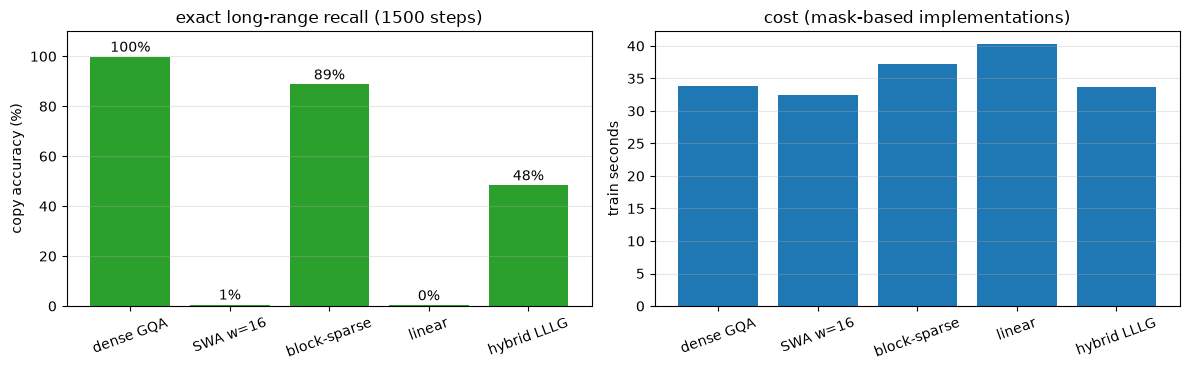

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
names = [r[0] for r in rows]
ax[0].bar(names, [100 * r[1] for r in rows], color="tab:green")
for i, r in enumerate(rows):
    ax[0].text(i, 100 * r[1] + 2, f"{100 * r[1]:.0f}%", ha="center")
ax[0].set_ylim(0, 110); ax[0].set_ylabel("copy accuracy (%)"); ax[0].set_title("exact long-range recall (1500 steps)")
ax[1].bar(names, [r[2] for r in rows]); ax[1].set_ylabel("train seconds"); ax[1].set_title("cost (mask-based implementations)")
for a in ax: a.tick_params(axis="x", rotation=20); a.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()

**Takeaways**
- **Induction heads appear suddenly.** After 300 steps even the dense model copies essentially nothing; by 1500 steps it is near-perfect. This "phase transition" is the induction-head mechanism described by Olsson et al. (Anthropic, 2022): two attention layers cooperate to find the previous occurrence of the current token and copy what followed it. Train too briefly and you would wrongly conclude the architecture cannot do the task.
- **Who can see far enough decides who can copy.** Dense attention sees everything. Block-sparse attention selects the relevant distant blocks by content and gets most of the way. SWA with `w=16` cannot see across the 30-token gap at all, and linear attention compresses the past into a fixed-size state that cannot hold an exact 12-token sequence. The hybrid (one global layer out of four) recovers part of the ability — the argument behind Gemma-3/Qwen3-Next-style hybrids, which in practice use more global layers and far longer training.
- Timing here reflects *mask-based* implementations; the asymptotic savings appear only with real kernels (FlexAttention, FlashAttention, Triton) at long sequence lengths.
- Decision rule: dense + GQA by default; SWA/hybrid when context ≥ 32k or KV-cache memory binds; linear/hybrid for ≥ 256k; learned block-sparse when you can afford the kernels — and always test exact long-range recall on your own data (needle-in-a-haystack, RULER).

**Next:** `04_ffn_moe.ipynb`.